<a href="https://colab.research.google.com/github/ThirumalReddyPeddi/Play-Store-App-Review-Analysis-Exploratory-Data-Analysis/blob/main/P2_4_14_Correlation_Heatmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Chart - 14 - **Correlation Heatmap**

In [ ]:
# Correlation Heatmap visualization code

In [ ]:
# Chart - 14 visualization code

# Useful for showing correlations between numerical variables.

# We will first clean the numerical columns and convert app sizes into MB.
#  This preparation is important because columns such as Installs, Price, and Size contain text characters.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of the original dataset
heatmap_df = playstore_data.copy()

# Convert Rating into numeric
heatmap_df['Rating'] = pd.to_numeric(
    heatmap_df['Rating'], errors='coerce'
)

# Convert Reviews into numeric
heatmap_df['Reviews'] = pd.to_numeric(
    heatmap_df['Reviews'].astype(str)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

# Convert Installs into numeric
heatmap_df['Installs'] = pd.to_numeric(
    heatmap_df['Installs'].astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False),
    errors='coerce'
)

# Convert Price into numeric
heatmap_df['Price'] = pd.to_numeric(
    heatmap_df['Price'].astype(str)
    .str.replace('$', '', regex=False),
    errors='coerce'
)

# Convert app Size into MB
def convert_size(size):
    size = str(size).strip().upper()

    if size.endswith('M'):
        return float(size[:-1])
    elif size.endswith('K'):
        return float(size[:-1]) / 1024
    else:
        return None

heatmap_df['Size_MB'] = heatmap_df['Size'].apply(convert_size)

# Remove invalid ratings
heatmap_df.loc[
    ~heatmap_df['Rating'].between(1, 5), 'Rating'
] = None

#####Q).What is the correlation between ratings, reviews, installs, and price?

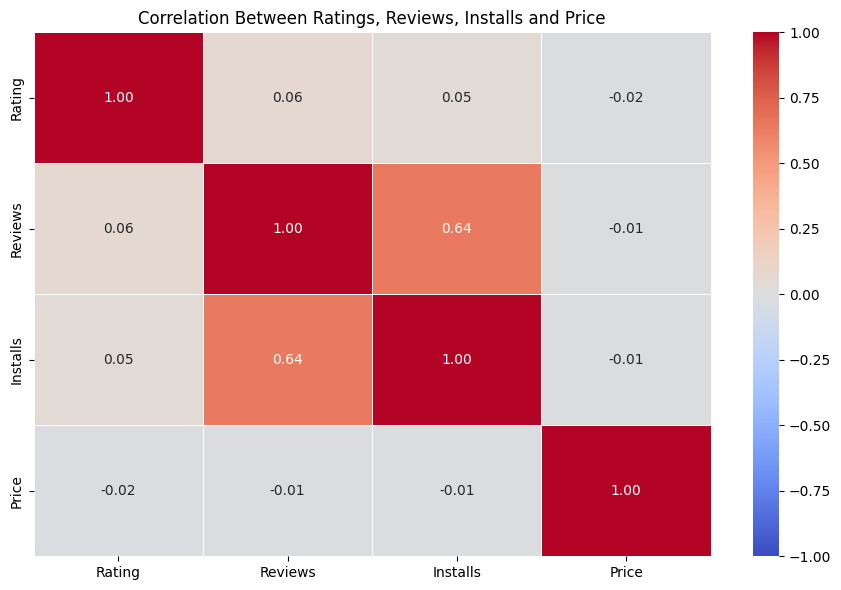

          Rating  Reviews  Installs  Price
Rating     1.000    0.063     0.045 -0.019
Reviews    0.063    1.000     0.643 -0.010
Installs   0.045    0.643     1.000 -0.012
Price     -0.019   -0.010    -0.012  1.000


In [ ]:
# Select numerical columns
corr_data = heatmap_df[
    ['Rating', 'Reviews', 'Installs', 'Price']
].dropna()

# Calculate correlation matrix
correlation_matrix = corr_data.corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Ratings, Reviews, Installs and Price')
plt.tight_layout()
plt.show()

# Display correlation values
print(correlation_matrix.round(3))

###### 1. Why did you pick the specific chart?

A heatmap was selected because it visually represents the correlation between multiple numerical variables using different colours and correlation values. It makes it easy to identify positive, negative, and weak relationships between ratings, reviews, installs, and price.

###### 2. What is/are the insight(s) found from the chart?

**The heatmap helps identify:**

Whether the number of reviews is positively associated with app installations.

Whether app ratings have a strong or weak relationship with reviews and installs.

Whether app price is associated with popularity or user ratings.

Which numerical variables have stronger or weaker correlations.

A positive correlation indicates that two variables tend to increase together, while a negative correlation indicates that one tends to decrease as the other increases.